# 01 Data Audit and EDA

**Objective:** verify the three immutable source lanes and decide whether their quality and distribution are sufficient to freeze a split.

**Success criteria:** no invalid image-label pairs, four-class counts are visible, and any warnings are reviewed before Notebook 02.


## Setup and reproducibility

Load the single tracked configuration, resolve all source paths, and create one immutable `data-audit` artifact run. This cell creates no dataset copies.


In [1]:
# Purpose: make the notebook runnable from either the project root or notebooks/.
# Inputs: tracked YAML configs and the three configured immutable source directories.
# Guard: create a unique artifact run before analysis so existing outputs are never overwritten.
# Output: initialized config, resolved paths, seed, and started run metadata.
from pathlib import Path
import sys

BOOTSTRAP_ROOT = Path.cwd().resolve()
if BOOTSTRAP_ROOT.name == "notebooks":
    BOOTSTRAP_ROOT = BOOTSTRAP_ROOT.parent
if str(BOOTSTRAP_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOTSTRAP_ROOT))

import pandas as pd
from IPython.display import display

from src.analysis.dataset_eda import (
    class_distribution,
    image_shape_summary,
    validation_decision,
)
from src.analysis.plot_utils import plot_class_distribution
from src.artifacts import (
    create_run,
    runtime_metadata,
    update_run_metadata,
    write_run_metadata,
)
from src.config import find_project_root, load_pipeline_config, resolve_project_path
from src.dataset.validate_yolo_dataset import (
    build_source_summary,
    validate_input_sources,
)

V2_ROOT = find_project_root(BOOTSTRAP_ROOT)
CONFIG = load_pipeline_config(V2_ROOT)
DATASET_CONFIG = CONFIG["dataset"]
CLASS_NAMES = CONFIG["classes"]
SEED = int(DATASET_CONFIG["random_seed"])
RUN = create_run(V2_ROOT, "data-audit", "ppe-v2-sources", SEED)
SOURCE_DIRS = {
    name: resolve_project_path(V2_ROOT, configured_path)
    for name, configured_path in DATASET_CONFIG["input"].items()
}
write_run_metadata(
    RUN,
    {
        "stage": "data-audit",
        "status": "started",
        "seed": SEED,
        "sources": {name: str(path) for name, path in SOURCE_DIRS.items()},
        "runtime": runtime_metadata(V2_ROOT),
    },
)

WindowsPath('C:/Github/smart-factory-safety-monitoring-system/ppe-detection/v2_pipeline/artifacts/20260825T170106Z_data-audit_ppe-v2-sources_s42_027537d/run.yaml')

## Validate all source lanes

**Input:** raw `open_source`, `factory_source`, and `test_source` folders.

**Expected result:** a compact source summary and a proceed/block decision. Malformed or duplicate annotation rows are invalid and block split freezing; warning rows require review.


In [2]:
# Purpose: perform the complete read-only integrity audit in one pass.
# Inputs: resolved source lanes, fixed four-class IDs, supported extensions, and empty-label policy.
# Guard: reject malformed or duplicate annotation rows while never copying, renaming, splitting, or augmenting source data.
# Output: one compact source summary CSV plus an explicit proceed/block decision.
validation_df = validate_input_sources(
    source_dirs=SOURCE_DIRS,
    class_ids=set(CLASS_NAMES),
    image_extensions=set(DATASET_CONFIG["valid_image_extensions"]),
    allow_empty_labels=bool(DATASET_CONFIG["allow_empty_labels"]),
)
source_summary_df = build_source_summary(validation_df, tuple(SOURCE_DIRS))
audit_decision = validation_decision(validation_df)
source_summary_df.to_csv(RUN.csv / "source_validation_summary.csv", index=False)

display(source_summary_df)
display(pd.DataFrame([audit_decision]))

,source,total_rows,valid_rows,invalid_rows,warning_rows,total_objects,num_person,num_helmet,num_vest,num_cleaning_coverall
0,open_source,180,180,0,38,1751,722,636,393,0
1,factory_source,859,859,0,38,4500,2050,1043,1279,128
2,test_source,117,117,0,0,419,214,97,78,30


,valid_rows,invalid_rows,warning_rows,can_proceed
0,1156,0,76,True


#### Observation

TODO after execution:

- Record invalid and warning counts.
- Identify the source lane requiring correction, if any.
- State whether the dataset may proceed to split freezing.


## Inspect class and image-shape distribution

**Input:** valid rows from the audit.

**Expected result:** one decision-relevant class-distribution figure and a small image-shape summary, without per-box tables.


,source,num_images,median_width,median_height,min_width,min_height,max_width,max_height
0,factory_source,859,2559.0,1439.0,1024,489,2948,1882
1,open_source,180,993.5,669.5,271,259,5760,3840
2,test_source,117,1672.0,1086.0,640,488,2948,1728


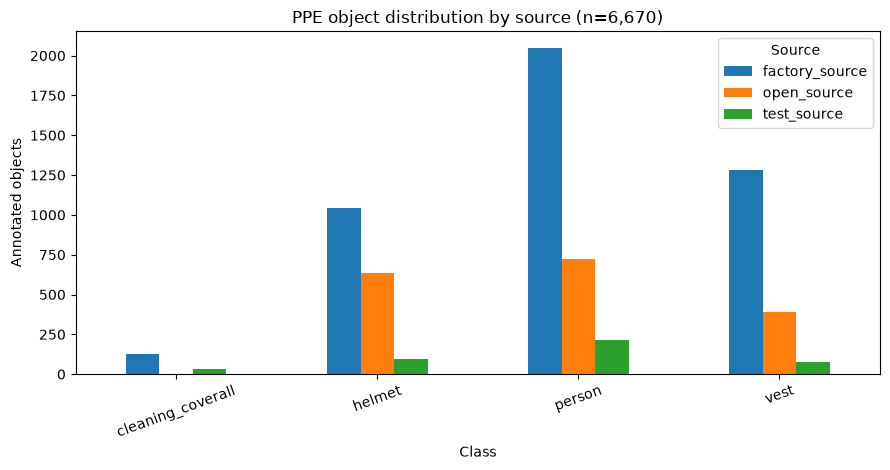

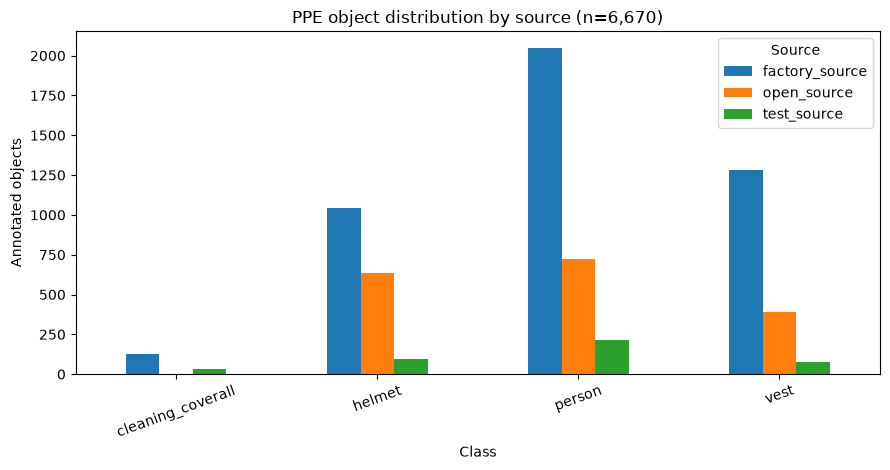

In [3]:
# Purpose: turn validated records into the two EDA summaries needed for modeling decisions.
# Inputs: the in-memory validation report, avoiding a second scan of the large image collection.
# Guard: aggregate by source/class and image shape; do not expose long per-image or per-box tables.
# Output: one labeled class-distribution figure and one small resolution summary.
class_distribution_df = class_distribution(validation_df, CLASS_NAMES)
image_shapes_df = image_shape_summary(validation_df)
class_figure_path = RUN.figures / "source_class_distribution.png"
class_figure = plot_class_distribution(class_distribution_df, class_figure_path)

display(image_shapes_df)
display(class_figure)

#### Observation

TODO after execution:

- Note meaningful source or class imbalance.
- Record whether image resolutions support the configured training size.
- Avoid conclusions based only on the independent final-test distribution.


## Review only actionable issues

**Input:** invalid or warning rows.

**Expected result:** at most ten actionable examples in the notebook. A complete issues CSV is created only when issues exist.


In [4]:
# Purpose: surface only rows that require human action or interpretation.
# Inputs: invalid rows and non-empty warning messages from the audit report.
# Guard: do not create an empty issues artifact or display an overwhelming full validation table.
# Output: at most ten examples in the notebook and a detailed CSV only when issues exist.
issues_df = validation_df.loc[
    validation_df["status"].ne("valid") | validation_df["warnings"].fillna("").ne(""),
    ["source", "image_name", "status", "errors", "warnings"],
].copy()
if issues_df.empty:
    print("No invalid rows or warnings found.")
else:
    issues_df.to_csv(RUN.csv / "validation_issues.csv", index=False)
    display(issues_df.head(10))

,source,image_name,status,errors,warnings
0,open_source,ppe_0008.jpg,valid,,Duplicate base name appears across sources; la...
1,open_source,ppe_0016.jpg,valid,,Duplicate base name appears across sources; la...
2,open_source,ppe_0018.jpg,valid,,Duplicate base name appears across sources; la...
3,open_source,ppe_0023.jpg,valid,,Duplicate base name appears across sources; la...
4,open_source,ppe_0037.jpg,valid,,Duplicate base name appears across sources; la...
5,open_source,ppe_0038.jpg,valid,,Duplicate base name appears across sources; la...
6,open_source,ppe_0048.jpg,valid,,Duplicate base name appears across sources; la...
7,open_source,ppe_0051.jpg,valid,,Duplicate base name appears across sources; la...
8,open_source,ppe_0052.jpg,valid,,Duplicate base name appears across sources; la...
9,open_source,ppe_0055.jpg,valid,,Duplicate base name appears across sources; la...


#### Observation

TODO after execution:

- Record recurring issue types rather than listing every filename.
- If invalid rows exist, stop here and fix source data before Notebook 02.


## Finalize the audit record

Write the final decision and the two descriptive artifact paths into `run.yaml`. No raw or generated dataset file is modified.


In [5]:
# Purpose: close the audit with machine-readable status and artifact references.
# Inputs: the proceed/block decision and paths produced by the preceding cells.
# Guard: objective metadata is persisted here; subjective interpretation remains in the Observation cell.
# Output: finalized run.yaml plus a concise run ID and decision message.
update_run_metadata(
    RUN,
    {
        "status": "accepted" if audit_decision["can_proceed"] else "blocked",
        "decision": audit_decision,
        "outputs": {
            "summary_csv": str(RUN.csv / "source_validation_summary.csv"),
            "class_distribution_figure": str(class_figure_path),
        },
    },
)
print(f"Audit run: {RUN.run_id}")
print(f"Decision: {'PROCEED' if audit_decision['can_proceed'] else 'BLOCK'}")

Audit run: 20260825T170106Z_data-audit_ppe-v2-sources_s42_027537d
Decision: PROCEED


#### Observation

TODO after execution: write the final audit decision and any required corrective action before running Notebook 02.
